In [30]:
import sys
RE_path = './'
sys.path.insert(1, RE_path)


In [32]:
import numpy as np
from matplotlib import pyplot as plt
import RE
import importlib
importlib.reload(RE)
from RE import *
import RESolver as solver
importlib.reload(solver)
import scipy.constants as const

# Example Solution using SPARC-like Parameters #

In [33]:
def getj0(I0,nx):
    r = np.linspace(0,1,nx)
    jp0 = 13.3e6 * (1-r**2)**0.5 # A/m**2
    javg = 2 * np.pi * np.trapz(jp0*r,x=r) / (np.pi * 1**2) # average jinit
    rmax = np.sqrt(I0 / (javg * np.pi)) # radius required to preserve total current
    return jp0, rmax

# Constants
R0 = 1.85 # [m]
a = 0.57 # [m]
Zeff = 1
T = 10 # eV
ne = 3e20 # per m**3
lnA = 15
eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
    
# Initial Conditions
jp0, rmax = getj0(8.7e6,128)
jr0 = np.zeros_like(jp0)

constants = [rmax, R0, ne, T, Zeff, lnA, eta]
init_conditions = [jp0, jr0]

Configure the solver

In [34]:
import RESolver as solver
importlib.reload(solver)

out = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=10e-3,
                        CFL=0.4,
                        RE_sources=[1,1,1,1], # [iDreicer, iTritBeta, iCompton, iAvalanche]
                        cre=0.1*3e8,
                        nprint=500,
                        verbose=True)



nx = 128

I0 [MA] = 8.71

Ir (t = 0) [MA] = 0

iDreicer = 1,iTritBeta = 1, iCompton = 1, iAvalanche = 1

Runaway Velocity [m/s]= 3e+07

Time Step dt [ms] = 0.000391

Seed Ir(t=dt) [MA] = 0.00435

step = 500, time [ms] = 0.20, Ip [MA] = 7.52, E/Ec [-] = 1071.69
step = 1000, time [ms] = 0.39, Ip [MA] = 6.81, E/Ec [-] = 897.22
step = 1500, time [ms] = 0.59, Ip [MA] = 6.25, E/Ec [-] = 708.62
step = 2000, time [ms] = 0.78, Ip [MA] = 5.80, E/Ec [-] = 535.40
step = 2500, time [ms] = 0.98, Ip [MA] = 5.44, E/Ec [-] = 393.32
step = 3000, time [ms] = 1.17, Ip [MA] = 5.15, E/Ec [-] = 283.26
step = 3500, time [ms] = 1.37, Ip [MA] = 4.93, E/Ec [-] = 200.94
step = 4000, time [ms] = 1.56, Ip [MA] = 4.77, E/Ec [-] = 140.91
step = 4500, time [ms] = 1.76, Ip [MA] = 4.66, E/Ec [-] = 97.98
step = 5000, time [ms] = 1.95, Ip [MA] = 4.57, E/Ec [-] = 67.74
step = 5500, time [ms] = 2.15, Ip [MA] = 4.52, E/Ec [-] = 46.64
step = 6000, time [ms] = 2.35, Ip [MA] = 4.48, E/Ec [-] = 32.05
step = 6500, time [ms] = 2.5

Show results

(0.0, 9.14079498765389)

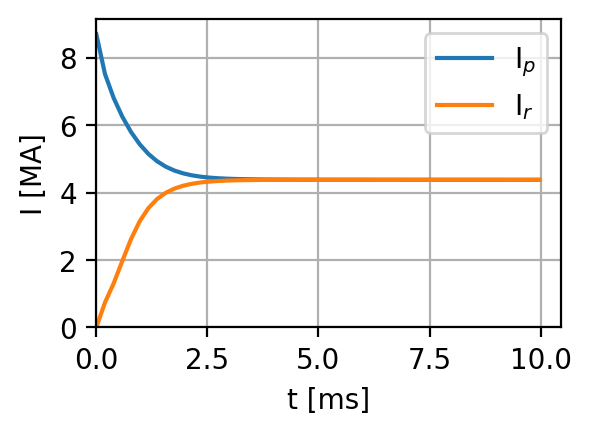

In [35]:
# Show Results
t, Ip, Ir = np.array(out['t']), np.array(out['Ip']), np.array(out['Ir'])
fig, axs = plt.subplots(1, 1, figsize=(3,2), dpi=200, sharex=True)

axs.plot(t * 1e3, Ip / 1e6, label='I$_p$')
axs.plot(t * 1e3, Ir / 1e6, label='I$_r$')
axs.set_xlabel('t [ms]')
axs.set_ylabel('I [MA]')
axs.grid()
axs.legend()
axs.set_xlim(xmin=0)
axs.set_ylim(ymin=0)



Final Profile

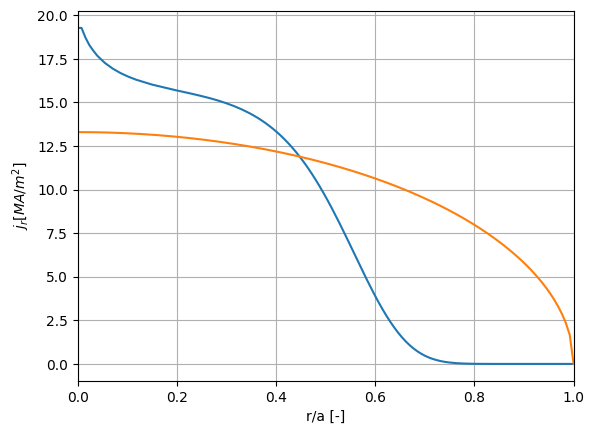

In [36]:
r = np.linspace(0,rmax,out['jr'].shape[0])

plt.plot(r/rmax,out['jr']/1e6)
plt.plot(r/rmax,jp0/1e6)
plt.xlabel('r/a [-]')
plt.ylabel('$j_r [MA/m^2]$')
plt.xlim([0,1])
plt.grid()

### With REs Turned on - Dreicer Source

nx = 128

I0 [MA] = 8.71

Ir (t = 0) [MA] = 0

iDreicer = 1,iTritBeta = 0, iCompton = 0, iAvalanche = 1

Runaway Velocity [m/s]= 3e+07

Time Step dt [ms] = 0.000293

Seed Ir(t=dt) [MA] = 0.00327



(0.0, 9.14079498765389)

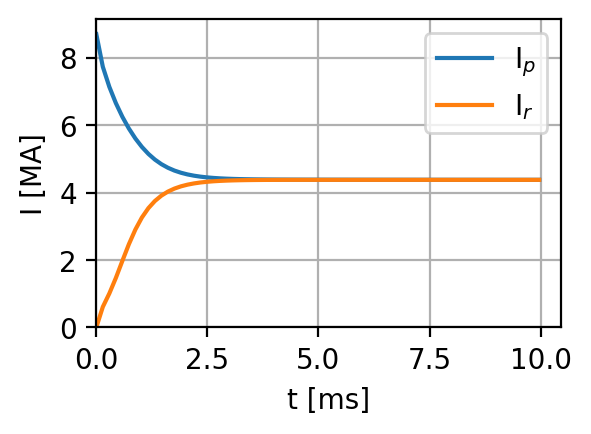

In [37]:
out = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=10e-3,
                        CFL=0.3,
                        RE_sources=[1,0,0,1],
                        cre=0.1*3e8,
                        nprint=500,
                        verbose=False)

# Show Results
t, Ip, Ir = np.array(out['t']), np.array(out['Ip']), np.array(out['Ir'])
fig, axs = plt.subplots(1, 1, figsize=(3,2), dpi=200, sharex=True)

axs.plot(t * 1e3, Ip / 1e6, label='I$_p$')
axs.plot(t * 1e3, Ir / 1e6, label='I$_r$')
axs.set_xlabel('t [ms]')
axs.set_ylabel('I [MA]')
axs.grid()
axs.legend()
axs.set_xlim(xmin=0)
axs.set_ylim(ymin=0)

# With Activated Sources only

nx = 128

I0 [MA] = 8.71

Ir (t = 0) [MA] = 0

iDreicer = 0,iTritBeta = 1, iCompton = 1, iAvalanche = 1

Runaway Velocity [m/s]= 3e+07

Time Step dt [ms] = 0.000293

Seed Ir(t=dt) [MA] = 7.34e-13



(0.0, 9.14079498765389)

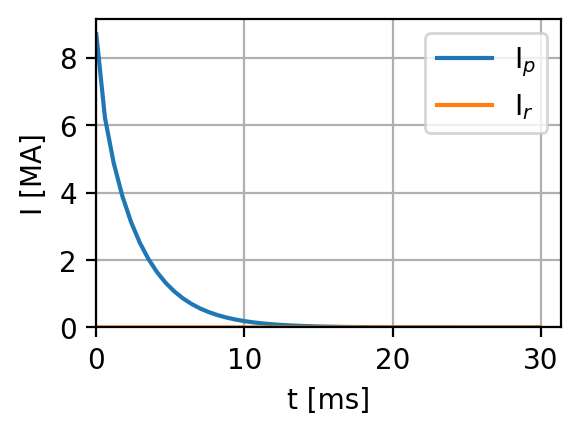

In [38]:
out = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=30e-3,
                        CFL=0.3,
                        RE_sources=[0,1,1,1],
                        cre=0.1*3e8,
                        nprint=2000,
                        verbose=False)

# Show Results
t, Ip, Ir = np.array(out['t']), np.array(out['Ip']), np.array(out['Ir'])
fig, axs = plt.subplots(1, 1, figsize=(3,2), dpi=200, sharex=True)

axs.plot(t * 1e3, Ip / 1e6, label='I$_p$')
axs.plot(t * 1e3, Ir / 1e6, label='I$_r$')
axs.set_xlabel('t [ms]')
axs.set_ylabel('I [MA]')
axs.grid()
axs.legend()
axs.set_xlim(xmin=0)
axs.set_ylim(ymin=0)
# axs.set_yscale('log')

# Trying to match NIMROD + DREAM simulations

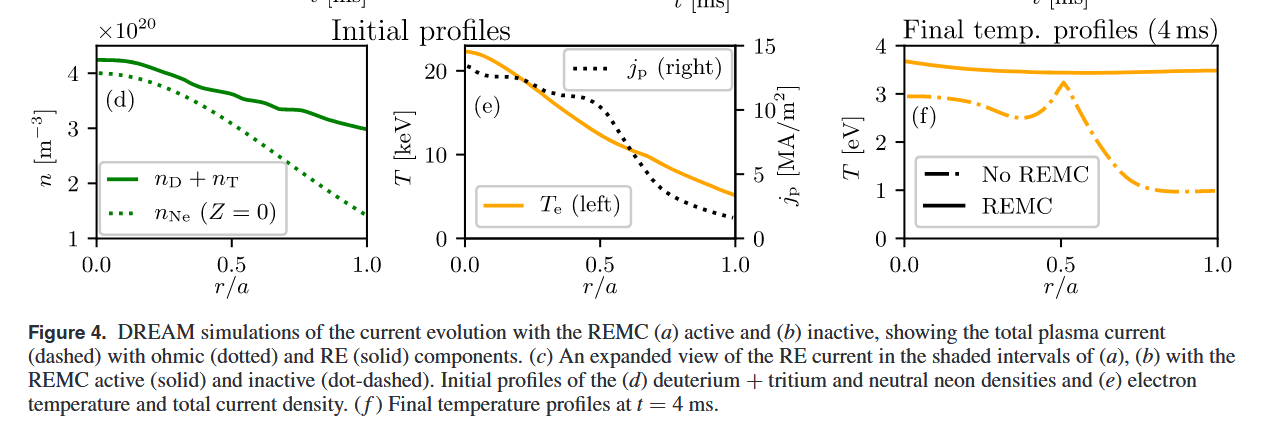

In [39]:
def getj0(I0,nx):
    r = np.linspace(0,1,nx)
    jp0 = 13.3e6 * (1-r**2)**0.7 # A/m**2
    javg = 2 * np.pi * np.trapz(jp0*r,x=r) / (np.pi * 1**2) # average jinit
    rmax = np.sqrt(I0 / (javg * np.pi)) # radius required to preserve total current
    return jp0, rmax

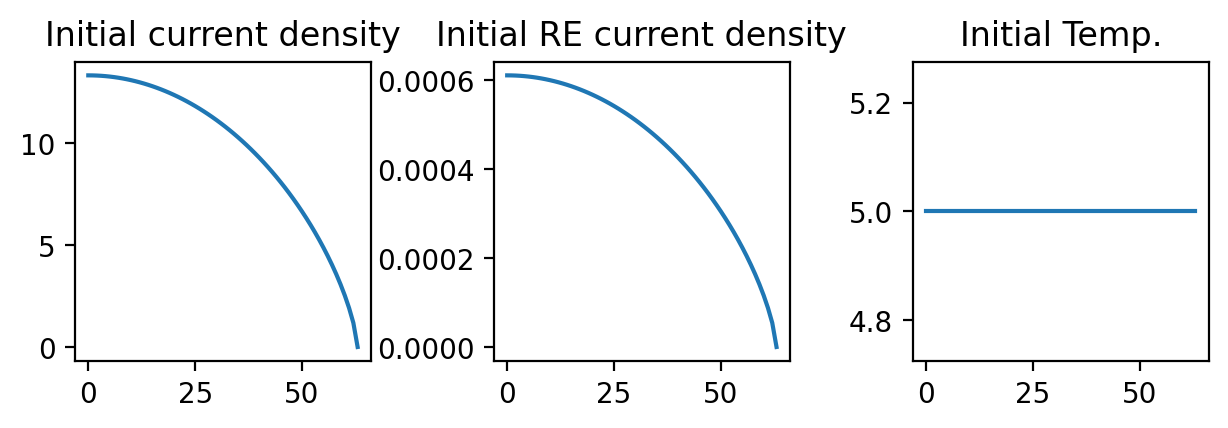

In [40]:
# Initial Conditions
jp0, rmax = getj0(8.7e6,64)
jr0 = 0.2 * jp0 * 2e3 / 8.7e6

# Constants
R0 = 1.87 # [m]
a = 0.57 * 1 # [m]
Zeff = 2
T = 5 * np.ones_like(jp0) # eV
ne = 6e20 # per m**3
lnA = 15
eta = 0.51 * getTransSpitzerResistivity(lnA,T,Zeff) * 0.01 # Ohm-m
    


constants = [rmax, R0, ne, T, Zeff, lnA, eta]
init_conditions = [jp0, jr0]

# Show Initial conditions
fig, axs = plt.subplots(1,3,figsize=(6,2),dpi=200)
axs[0].plot(jp0/1e6)
axs[0].set_title('Initial current density')
axs[1].plot(jr0/1e6)
axs[1].set_title('Initial RE current density')
axs[2].plot(T)
axs[2].set_title('Initial Temp.')

fig.tight_layout(pad=0.2)

In [41]:
import RESolver as solver
importlib.reload(solver)

out = solver.solve(constants=constants,
                        init_conditions=init_conditions,
                        tmax=2e-3,
                        CFL=0.1,
                        RE_sources=[1,0,0,1],
                        cre=0.1*3e8,
                        nprint=50,
                        verbose=False,
                        RE_start=0)



nx = 64

I0 [MA] = 8.71

Ir (t = 0) [MA] = 0.0004

iDreicer = 1,iTritBeta = 0, iCompton = 0, iAvalanche = 1

Runaway Velocity [m/s]= 3e+07

Time Step dt [ms] = 7.96e-05

Seed Ir(t=dt) [MA] = 0.232



(0.0, 9.142402972524827)

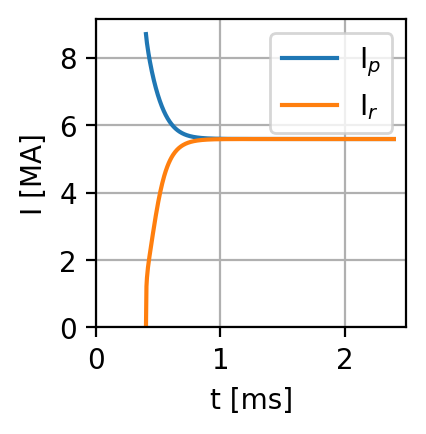

In [42]:
# Show Results
t, Ip, Ir = np.array(out['t']), np.array(out['Ip']), np.array(out['Ir'])
fig, axs = plt.subplots(1, 1, figsize=(2,2), dpi=200, sharex=True)

axs.plot(t * 1e3 + 0.4, Ip / 1e6, label='I$_p$')
axs.plot(t * 1e3 + 0.4, Ir / 1e6, label='I$_r$')
axs.set_xlabel('t [ms]')
axs.set_ylabel('I [MA]')
axs.grid()
axs.legend()
axs.set_xlim(xmin=0)
axs.set_ylim(ymin=0)

